# Initial Selection of Sources 

Ragadeepika Pucha, Stéphanie Juneau, Arjun Dey, Yao-Yuan Mao, and others ... <br/>

This notebook combines the different DESI DR1 catalogs and creates the starting catalog

In [1]:
import numpy as np
import sys
sys.path.append('/global/cfs/cdirs/desi/users/raga19/repos/DESI_Project/py/')

from astropy.io import fits
from astropy.table import Table, Column, join

import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm

from desispec.io import specprod_root

import utils
import warnings
warnings.filterwarnings('ignore')

In [2]:
## Setting up plots

settings = {
    'font.size':22,
    'axes.linewidth':3.0,
    'xtick.major.size':6.0,
    'xtick.minor.size':4.0,
    'xtick.major.width':3.0,
    'xtick.minor.width':1.5,
    'xtick.direction':'in', 
    'xtick.minor.visible':True,
    'xtick.top':True,
    'ytick.major.size':6.0,
    'ytick.minor.size':4.0,
    'ytick.major.width':3.0,
    'ytick.minor.width':1.5,
    'ytick.direction':'in', 
    'ytick.minor.visible':True,
    'ytick.right':True
}

plt.rcParams.update(**settings)

### 1. Redshift Catalog

In [3]:
specprod = 'iron'
specprod_dir = specprod_root(specprod)

In [4]:
zcat_dir = f'{specprod_dir}/zcatalog/v1'
zcat_file = f'zall-pix-{specprod}.fits'
zcat = Table.read(f'{zcat_dir}/{zcat_file}')

In [5]:
len(zcat)

28425963

In [6]:
good_fiber = (zcat['COADD_FIBERSTATUS'].data == 0)
good_redshift = (zcat['ZWARN'] == 0)|(zcat['ZWARN'] == 4)
spectype = (zcat['SPECTYPE'].astype(str) == 'GALAXY')|(zcat['SPECTYPE'].astype(str) == 'QSO')
zcat_prim = zcat['ZCAT_PRIMARY']
zcut = (zcat['Z'].data >= 0.001)&(zcat['Z'].data <= 0.45)

In [7]:
print ('Total number of spectra (rows):', len(zcat))
print ('Number of PRIMARY spectra:', len(zcat[zcat['ZCAT_PRIMARY']]))
print ('Number of PRIMARY spectra with good fiber:', len(zcat[zcat_prim&good_fiber]))
print ('Number of PRIMARY spectra with good redshift:', len(zcat[zcat_prim&good_redshift]))
print ('Number of PRIMARY spectra with good spectra and good redshifts:',len(zcat[zcat_prim&good_redshift&good_fiber]))
print ('Number of PRIMARY spectra with good spectra and good redshits, and is a GALAXY|QSO:', len(zcat[zcat_prim&good_redshift&good_fiber&spectype]))
print ('Number of PRIMARY spectra with good spectra and good redshits, and is a GALAXY|QSO, with 0.001 <= z <= 0.45:', len(zcat[zcat_prim&good_redshift&good_fiber&spectype&zcut]))

Total number of spectra (rows): 28425963
Number of PRIMARY spectra: 27547223
Number of PRIMARY spectra with good fiber: 22726204
Number of PRIMARY spectra with good redshift: 21807264
Number of PRIMARY spectra with good spectra and good redshifts: 21801821
Number of PRIMARY spectra with good spectra and good redshits, and is a GALAXY|QSO: 17197897
Number of PRIMARY spectra with good spectra and good redshits, and is a GALAXY|QSO, with 0.001 <= z <= 0.45: 7434906


In [8]:
## Add 'SPECPROD' column
col = Column([specprod]*len(zcat), name = 'SPECPROD')
zcat.add_column(col, 0)

In [9]:
prim_cuts = zcat_prim&good_redshift&good_fiber&spectype&zcut

In [10]:
sel_columns = ['TARGETID', 'SPECPROD', 'SURVEY', 'PROGRAM', 'HEALPIX', \
               'TARGET_RA', 'TARGET_DEC', 'SPECTYPE', 'DELTACHI2', \
               'DESI_TARGET', 'SV1_DESI_TARGET', 'SV2_DESI_TARGET', 'SV3_DESI_TARGET', \
               'BGS_TARGET', 'SV1_BGS_TARGET', 'SV2_BGS_TARGET', 'SV3_BGS_TARGET', \
               'SCND_TARGET', 'SV1_SCND_TARGET', 'SV2_SCND_TARGET', 'SV3_SCND_TARGET', 'ZCAT_NSPEC', 'ZCAT_PRIMARY']

zcat_sel = zcat[prim_cuts][sel_columns]

In [11]:
len(zcat), len(zcat_sel)

(28425963, 7434906)

### 2. Join with LS DR9

In [12]:
t_ls = Table.read('../catalogs/tractorphot-iron.fits')

In [13]:
ls_columns = ['TARGETID', 'RELEASE', 'FLUX_G', 'FLUX_R', 'FLUX_Z', \
              'FLUX_W1', 'FLUX_W2', 'FLUX_W3', 'FLUX_W4', \
              'FLUX_IVAR_G', 'FLUX_IVAR_R', 'FLUX_IVAR_Z', \
              'FLUX_IVAR_W1', 'FLUX_IVAR_W2', 'FLUX_IVAR_W3', 'FLUX_IVAR_W4', \
              'MW_TRANSMISSION_G', 'MW_TRANSMISSION_R', 'MW_TRANSMISSION_Z', \
              'MW_TRANSMISSION_W1', 'MW_TRANSMISSION_W2', 'MW_TRANSMISSION_W3', 'MW_TRANSMISSION_W4', \
              'FIBERFLUX_G', 'FIBERFLUX_R', 'FIBERFLUX_Z', 'FRACFLUX_G', 'FRACFLUX_R', 'FRACFLUX_Z', \
              'TYPE', 'SERSIC', 'SERSIC_IVAR']

tsel_ls = t_ls[ls_columns]

In [14]:
zcat_lsdr9 = join(zcat_sel, tsel_ls, keys = ['TARGETID'], join_type = 'left')

In [15]:
len(zcat_lsdr9), len(zcat_sel)

(7434906, 7434906)

In [16]:
for col in ls_columns:
    if (col == 'TYPE'):
        zcat_lsdr9[col].fill_value = ''
    else:
        zcat_lsdr9[col].fill_value = 0

zcat_lsdr9 = zcat_lsdr9.filled()

In [17]:
_, snr_g = utils.tractor_flux_to_mag(zcat_lsdr9, 'G')
_, snr_r = utils.tractor_flux_to_mag(zcat_lsdr9, 'R')
_, snr_z = utils.tractor_flux_to_mag(zcat_lsdr9, 'Z')

fracflux_g = zcat_lsdr9['FRACFLUX_G'].data
fracflux_r = zcat_lsdr9['FRACFLUX_R'].data
fracflux_z = zcat_lsdr9['FRACFLUX_Z'].data

snr_sel = (snr_g >= 5)&(snr_r >= 5)&(snr_z >= 5)
fracflux_sel = (fracflux_g <= 0.25)&(fracflux_r <= 0.25)&(fracflux_z <= 0.25)

len(zcat_lsdr9[snr_sel&fracflux_sel])

6856046

In [18]:
zcat_lsdr9 = zcat_lsdr9[snr_sel&fracflux_sel]

In [19]:
del t_ls

### 3. Join with CIGALE Stellar Mass Catalog

In [20]:
tmass = Table.read('/global/cfs/cdirs/desicollab/science/gqp/stellar_masses_sed_cigale_agn/iron/v1.2/IronPhysProp_v1.2.fits')
len(tmass)

17149172

In [21]:
## Select only some columns
mass_cols = ['TARGETID', 'SURVEY', 'PROGRAM', 'HEALPIX', 'CHI2', \
            'LOGM', 'LOGM_ERR', 'LOGSFR', 'LOGSFR_ERR', 'AGNLUM', 'AGNFRAC', 'AGNPSY', \
            'FLAG_MASSPDF', 'FLAG_SFRPDF', 'FLAGOPTICAL', 'FLAGINFRARED']

tmass_sel = tmass[mass_cols]

In [22]:
zcat_lsdr9_mass = join(zcat_lsdr9, tmass_sel, keys = ['TARGETID', 'SURVEY', 'PROGRAM', 'HEALPIX'], join_type = 'left')

In [23]:
for col in mass_cols:
    zcat_lsdr9_mass[col].fill_value = -99
    
zcat_lsdr9_mass = zcat_lsdr9_mass.filled()

In [24]:
len(zcat_lsdr9), len(zcat_lsdr9_mass), len(zcat_lsdr9_mass[zcat_lsdr9_mass['LOGM'].data == -99]), len(zcat_lsdr9_mass[zcat_lsdr9_mass['LOGM'].data == 0])

(6856046, 6856046, 0, 163364)

In [25]:
## CIGALE Selection Cuts
## logmass > 6, logmass_err <= 0.5, chi2 <= 10, 0.2 < mass_pdf < 5

logmass = zcat_lsdr9_mass['LOGM'].data
logmass_err = zcat_lsdr9_mass['LOGM_ERR'].data
chi2 = zcat_lsdr9_mass['CHI2'].data
mass_pdf = zcat_lsdr9_mass['FLAG_MASSPDF'].data

logmass_cond = (logmass >= 6)#&(logmass <= 12)
logmasserr_cond = (logmass_err > 0)&(logmass_err <= 0.5)
chi2_cond = (chi2 > 0)&(chi2 <= 10)
pdf_cond = (mass_pdf >= 0.2)&(mass_pdf <= 5)

mass_sel_cond = logmass_cond&logmasserr_cond&chi2_cond&pdf_cond

In [26]:
zcat_ls_mass = zcat_lsdr9_mass[mass_sel_cond]

In [27]:
len(zcat_ls_mass)

6143599

In [28]:
del tmass

In [29]:
logmass = zcat_ls_mass['LOGM'].data
lomass = (logmass <= 9.5)

mtype = zcat_ls_mass['TYPE'].astype(str).data
is_psf = (mtype == 'PSF')

In [30]:
print ('Min, Max, Median, Stellar Mass', min(logmass), max(logmass), np.median(logmass))
print ('Number of Dwarf Galaxies: ', len(zcat_ls_mass[lomass]), round(len(zcat_ls_mass[lomass])*100/len(zcat_ls_mass), 1), '%')
print ('Number of Massive Galaxies: ', len(zcat_ls_mass[~lomass]), round(len(zcat_ls_mass[~lomass])*100/len(zcat_ls_mass), 1), '%')
print ('Number of points sources: ', len(zcat_ls_mass[is_psf]), round(len(zcat_ls_mass[is_psf])*100/len(zcat_ls_mass), 1), '%')

Min, Max, Median, Stellar Mass 6.000074658726291 13.663359160576434 10.345776219594809
Number of Dwarf Galaxies:  995884 16.2 %
Number of Massive Galaxies:  5147715 83.8 %
Number of points sources:  171799 2.8 %


### 4. Join with EmFit

In [31]:
t_em = Table.read('/global/cfs/cdirs/desicollab/science/gqp/emfit/v2.3/emfit-dr1-v2.3.fits')

In [32]:
## Join with EmFit

t_zcat_em = join(zcat_ls_mass, t_em, keys = ['TARGETID', 'SPECPROD', 'SURVEY', 'PROGRAM', 'HEALPIX'], join_type = 'inner')

In [33]:
len(zcat_ls_mass), len(t_em), len(t_zcat_em)

(6143599, 7378347, 6099572)

In [34]:
del t_em

### 5. Join with QN Redshifts

In [35]:
fastfile = '/global/cfs/cdirs/desicollab/spectro/fastspecfit/iron/v2.1/catalogs/fastspec-iron.fits'

In [36]:
h_fast = fits.open(fastfile)
t_fast = Table(h_fast['FASTSPEC'].data)

In [37]:
fast_cols = ['TARGETID', 'SURVEY', 'PROGRAM', 'HEALPIX', 'Z']

t_fast = t_fast[fast_cols]
t_fast.rename_column('Z', 'Z_QN')

In [38]:
t_zcat_em_qn = join(t_zcat_em, t_fast, keys = ['TARGETID', 'SURVEY', 'PROGRAM', 'HEALPIX'])

In [39]:
len(t_zcat_em), len(t_zcat_em_qn)

(6099572, 6099572)

In [40]:
## Select sources with Z_QN <= 0.45 --> Remove the rest

tsel_zcat_em = t_zcat_em_qn[t_zcat_em_qn['Z_QN'].data <= 0.45]

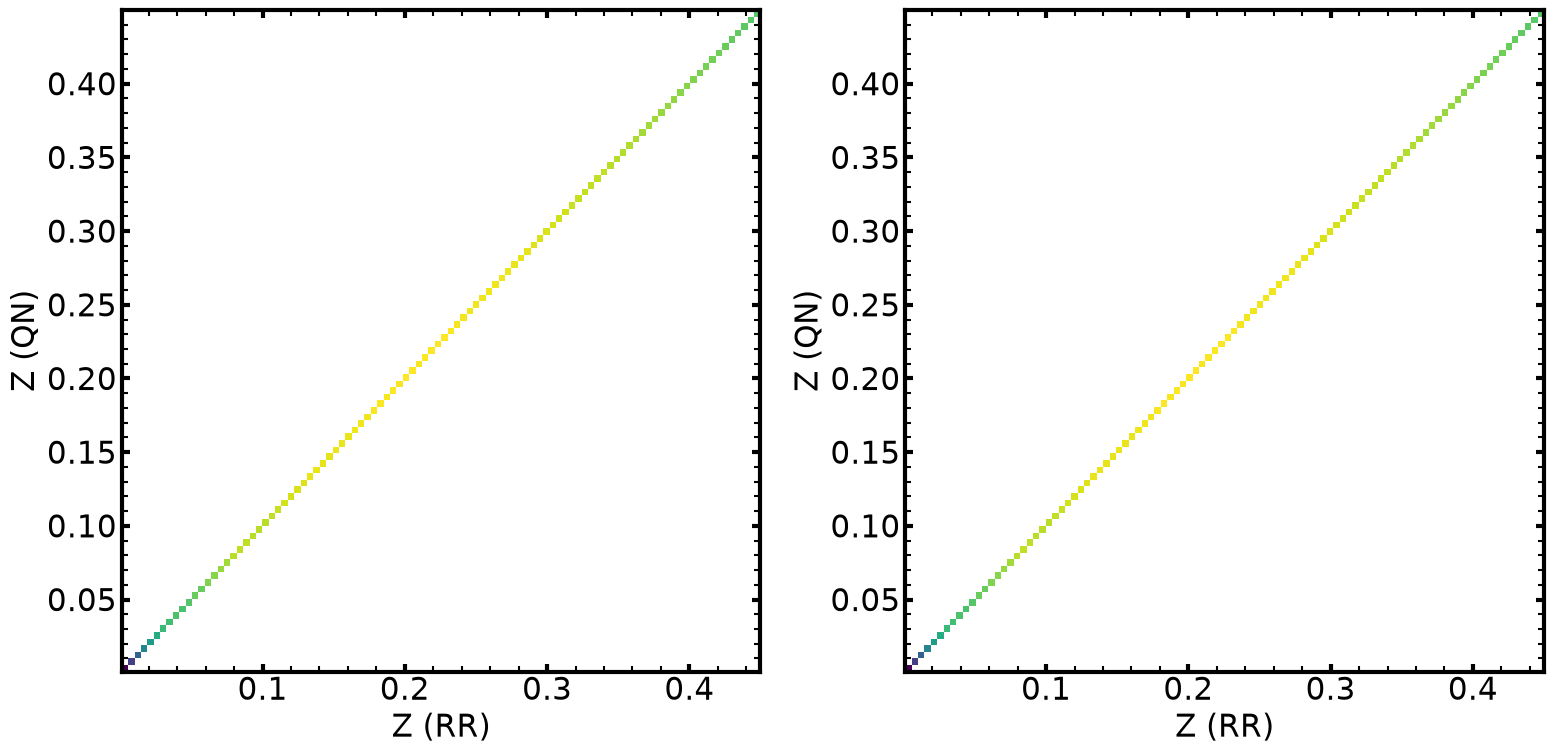

In [41]:
## Plot Z vs Z_QN

plt.figure(figsize = (16,8))

plt.subplot2grid((1,2), (0,0))
plt.hist2d(t_zcat_em_qn['Z'], t_zcat_em_qn['Z_QN'], bins = 100, norm = LogNorm())
plt.xlabel('Z (RR)')
plt.ylabel('Z (QN)')

plt.subplot2grid((1,2), (0,1))
plt.hist2d(tsel_zcat_em['Z'], tsel_zcat_em['Z_QN'], bins = 100, norm = LogNorm())
plt.xlabel('Z (RR)')
plt.ylabel('Z (QN)')

plt.tight_layout()

In [42]:
len(t_zcat_em), len(t_zcat_em_qn), len(tsel_zcat_em), len(t_zcat_em_qn) - len(tsel_zcat_em)

(6099572, 6099572, 6099572, 0)

In [43]:
del t_fast

In [44]:
t_final = tsel_zcat_em

In [45]:
len(tsel_zcat_em), len(t_final)

(6099572, 6099572)

### All Numbers

In [46]:
print ('Original Zall catalog: ', len(zcat))
print ('Applying Cuts on Zall: ', len(zcat_sel))
print ('Joining with LS DR9 photometry and applying cuts: ', len(zcat_lsdr9))
print ('Joining with CIGALE and applying cuts: ', len(zcat_ls_mass))
print ('Joining with EmFit: ', len(t_zcat_em))
print ('Removing Z_QN > 0.45: ', len(t_final))

Original Zall catalog:  28425963
Applying Cuts on Zall:  7434906
Joining with LS DR9 photometry and applying cuts:  6856046
Joining with CIGALE and applying cuts:  6143599
Joining with EmFit:  6099572
Removing Z_QN > 0.45:  6099572


In [47]:
del zcat
del zcat_sel
del t_zcat_em
del tsel_zcat_em
del zcat_lsdr9

### Saving the Final Catalog

In [48]:
# t_final.write('../catalogs/iron-selection-v2.3.fits', overwrite = True)

---